# Latent affine registration with a sign-only template

Same saved inverted latents and six-parameter affine setup as `latent_affine_registration.ipynb`, with the access restriction from the sign-template notebooks: the optimizer sees only the **sign** of the baseline inversion as a 0/1 field. The observation is still the full signed condition latent.

A random 0/1 control (same shape, independent draws) is registered to the same observation. If that arm recovers high bit accuracy or locks onto the expected transform, correspondences are being invented.

Kept fast for local runs: few samples, coarse init grids, L-BFGS-B only (no differential evolution). Results go to `results/latent_affine_registration_sign_template/`.


## 1. Configuration and data


In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import ndimage
from scipy.optimize import minimize
from scipy.stats import pearsonr

RUN_DIR = Path("results/geometric_registration/latent_undo_n5")
LATENT_DIR = RUN_DIR / "latents"
OUTPUT_DIR = Path("results/latent_affine_registration_sign_template")
FIGURES_DIR = OUTPUT_DIR / "figures"

# Keep wall time under ~5 minutes locally.
MAX_SAMPLES = 2
WARP_ORDER = 1
VALID_RADIUS_FRAC = 0.32
SEED = 42
COARSE_ANGLE_STEP = 4.0
COARSE_TRANSLATION_STEP = 1.0

PARAM_NAMES = ["angle_deg", "scale_x", "scale_y", "shear", "tx", "ty"]
ANGLE_RANGE = (-20.0, 20.0)
SCALE_RANGE = (0.85, 1.15)
SHEAR_RANGE = (-0.2, 0.2)
TRANSLATION_RANGE = (-4.0, 4.0)
BOUNDS = [ANGLE_RANGE, SCALE_RANGE, SCALE_RANGE, SHEAR_RANGE, TRANSLATION_RANGE, TRANSLATION_RANGE]
LB = np.array([b[0] for b in BOUNDS], dtype=float)
UB = np.array([b[1] for b in BOUNDS], dtype=float)
SCIPY_BOUNDS = list(zip(LB, UB))

FAMILIES = ["horizontal_translation", "vertical_translation", "rotation"]
FAMILY_TITLES = {
    "horizontal_translation": "horizontal shift (image px)",
    "vertical_translation": "vertical shift (image px)",
    "rotation": "rotation (deg)",
}

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not LATENT_DIR.is_dir():
    raise SystemExit(f"Missing {LATENT_DIR}. Copy latent_undo_n5 from HiPerGator first.")

meta = json.loads((RUN_DIR / "metadata.json").read_text(encoding="utf-8"))
VAE_SCALE = int(meta["vae_scale_factor"])
CONDITIONS = [(row["transformation_type"], float(row["magnitude"])) for row in meta["conditions"]]
N_SAMPLES = min(MAX_SAMPLES, int(meta["num_samples"]))

blobs = []
for sample_id in range(N_SAMPLES):
    path = LATENT_DIR / f"sample_{sample_id:03d}.pt"
    if not path.is_file():
        raise SystemExit(f"missing {path}")
    blobs.append(torch.load(path, map_location="cpu", weights_only=True))

print(f"loaded {len(blobs)} / {meta['num_samples']} samples from {LATENT_DIR}")
print(f"VAE scale={VAE_SCALE}, conditions={len(CONDITIONS)}")
print(f"output -> {OUTPUT_DIR.resolve()}")


loaded 2 / 5 samples from results\geometric_registration\latent_undo_n5\latents
VAE scale=8, conditions=13
output -> C:\Users\samco\OneDrive\Desktop\gaussian_rotation\results\latent_affine_registration_sign_template


## 2. Method

**Pair.** Template bits come from the baseline inversion \(B=\mathbf{1}[z_{\mathrm{hat},0}\ge 0]\) (all four channels). The observation is the full signed condition latent \(Y=z_{\mathrm{hat}}\).

**Objective.** With \(B_\pm=2B-1\), maximize multi-channel
\(\mathrm{corr}\bigl(W_{A,t}(B_\pm),\,Y\bigr)\)
on a fixed circular mask (same affine shared across channels).

**Evaluation.** Inverse-warp \(Y\) and compare its sign to \(B_\pm\) (bit accuracy / bit MSE). Also apply that inverse to the full \(Y\) and score Pearson / RMSE against the original Gaussian \(z\), as in the full-value notebook.

**Random control.** An independent 0/1 field with the same shape is registered to the same \(Y\).


In [2]:
def latent_key(kind: str, magnitude: float) -> str:
    return f"z_hat__{kind}__{magnitude:.1f}"


def as_chw(tensor) -> np.ndarray:
    array = np.asarray(tensor, dtype=np.float64)
    if array.ndim == 4 and array.shape[0] == 1:
        array = array[0]
    if array.ndim != 3:
        raise ValueError(f"expected (C,H,W), got {array.shape}")
    return array


def params_to_matrix(params: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    angle, sx, sy, shear, tx, ty = np.asarray(params, dtype=float)
    theta = np.deg2rad(angle)
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    rotation = np.array([[cos_t, -sin_t], [sin_t, cos_t]], dtype=float)
    linear = np.array([[sx, sx * shear], [0.0, sy]], dtype=float)
    return rotation @ linear, np.array([tx, ty], dtype=float)


def image_center(spatial_shape: tuple[int, int]) -> np.ndarray:
    return np.array(spatial_shape, dtype=float) / 2.0 - 0.5


def warp_chw(latent: np.ndarray, matrix: np.ndarray, translation: np.ndarray) -> np.ndarray:
    center = image_center(latent.shape[-2:])
    inverse = np.linalg.inv(matrix)
    affine = np.zeros((2, 3), dtype=float)
    affine[:, :2] = inverse
    affine[:, 2] = -inverse @ (center + translation) + center
    channels = [
        ndimage.affine_transform(
            channel,
            affine,
            order=WARP_ORDER,
            mode="constant",
            cval=0.0,
            prefilter=True,
        )
        for channel in latent
    ]
    return np.stack(channels, axis=0)


def invert_params(params: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    matrix, translation = params_to_matrix(params)
    inverse = np.linalg.inv(matrix)
    return inverse, -inverse @ translation


def circular_valid_mask(spatial_shape: tuple[int, int], radius_frac: float = VALID_RADIUS_FRAC) -> np.ndarray:
    height, width = spatial_shape
    center_y, center_x = image_center(spatial_shape)
    rows, cols = np.mgrid[0:height, 0:width]
    radius = radius_frac * float(min(height, width))
    return (rows - center_y) ** 2 + (cols - center_x) ** 2 <= radius ** 2


def expected_params(kind: str, magnitude: float, vae_scale: int = VAE_SCALE) -> np.ndarray:
    if kind == "baseline" or magnitude == 0.0:
        return np.array([0.0, 1.0, 1.0, 0.0, 0.0, 0.0], dtype=float)
    if kind == "horizontal_translation":
        return np.array([0.0, 1.0, 1.0, 0.0, magnitude / vae_scale, 0.0], dtype=float)
    if kind == "vertical_translation":
        return np.array([0.0, 1.0, 1.0, 0.0, 0.0, magnitude / vae_scale], dtype=float)
    if kind == "rotation":
        return np.array([magnitude, 1.0, 1.0, 0.0, 0.0, 0.0], dtype=float)
    raise ValueError(kind)


def bits_from_latent(latent: np.ndarray) -> np.ndarray:
    return (np.asarray(latent) >= 0).astype(np.float64)


def bits_to_pm(bits01: np.ndarray) -> np.ndarray:
    return 2.0 * bits01 - 1.0


def sign_pm(latent: np.ndarray) -> np.ndarray:
    return np.where(np.asarray(latent) >= 0, 1.0, -1.0)


def masked_vectors(a: np.ndarray, b: np.ndarray, mask: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    return a[:, mask].ravel(), b[:, mask].ravel()


def full_latent_corr(a: np.ndarray, b: np.ndarray, mask: np.ndarray | None = None) -> float:
    if mask is None:
        left, right = a.ravel(), b.ravel()
    else:
        left, right = masked_vectors(a, b, mask)
    if left.size < 2 or np.std(left) < 1e-12 or np.std(right) < 1e-12:
        return 0.0
    return float(pearsonr(left, right).statistic)


def full_latent_rmse(a: np.ndarray, b: np.ndarray, mask: np.ndarray | None = None) -> float:
    if mask is None:
        residual = a.ravel() - b.ravel()
    else:
        residual = a[:, mask].ravel() - b[:, mask].ravel()
    return float(np.sqrt(np.mean(residual ** 2)))


def bit_metrics(bits01: np.ndarray, observation: np.ndarray, params: np.ndarray, mask: np.ndarray) -> dict:
    bits_pm = bits_to_pm(bits01)
    forward = warp_chw(bits_pm, *params_to_matrix(params))
    inverse_matrix, inverse_translation = invert_params(params)
    back = warp_chw(observation, inverse_matrix, inverse_translation)
    signed_back = sign_pm(back)
    bits_m, signed_m = masked_vectors(bits_pm, signed_back, mask)
    _, back_m = masked_vectors(bits_pm, back, mask)
    return {
        "forward_correlation": full_latent_corr(forward, observation, mask),
        "bit_accuracy": float(np.mean(bits_m == signed_m)),
        "bit_mse": float(np.mean((bits_m - signed_m) ** 2)),
        "continuous_correlation": full_latent_corr(bits_pm, back, mask),
        "continuous_mse": float(np.mean((bits_m - back_m) ** 2)),
    }


SHAPE = as_chw(blobs[0]["z"]).shape
VALID_MASK = circular_valid_mask(SHAPE[-2:])
print(f"latent shape {SHAPE}, valid pixels/channel={int(VALID_MASK.sum())} ({100 * VALID_MASK.mean():.1f}%)")


latent shape (4, 64, 64), valid pixels/channel=1304 (31.8%)


In [3]:
def forward_correlation(bits_pm: np.ndarray, observation: np.ndarray, params: np.ndarray, mask: np.ndarray) -> float:
    warped = warp_chw(bits_pm, *params_to_matrix(params))
    return full_latent_corr(warped, observation, mask)


def coarse_initialize(bits_pm: np.ndarray, observation: np.ndarray, mask: np.ndarray) -> np.ndarray:
    identity = np.array([0.0, 1.0, 1.0, 0.0, 0.0, 0.0], dtype=float)
    best_params = identity.copy()
    best_corr = forward_correlation(bits_pm, observation, best_params, mask)

    for angle in np.arange(ANGLE_RANGE[0], ANGLE_RANGE[1] + 0.5 * COARSE_ANGLE_STEP, COARSE_ANGLE_STEP):
        params = np.array([angle, 1.0, 1.0, 0.0, 0.0, 0.0], dtype=float)
        corr = forward_correlation(bits_pm, observation, params, mask)
        if corr > best_corr:
            best_corr = corr
            best_params = params

    for tx in np.arange(TRANSLATION_RANGE[0], TRANSLATION_RANGE[1] + 0.5 * COARSE_TRANSLATION_STEP, COARSE_TRANSLATION_STEP):
        for ty in np.arange(TRANSLATION_RANGE[0], TRANSLATION_RANGE[1] + 0.5 * COARSE_TRANSLATION_STEP, COARSE_TRANSLATION_STEP):
            params = np.array([0.0, 1.0, 1.0, 0.0, tx, ty], dtype=float)
            corr = forward_correlation(bits_pm, observation, params, mask)
            if corr > best_corr:
                best_corr = corr
                best_params = params

    angle0, _, _, _, tx0, ty0 = best_params
    for angle in np.unique(np.clip([angle0 - COARSE_ANGLE_STEP, angle0, angle0 + COARSE_ANGLE_STEP], *ANGLE_RANGE)):
        for tx in np.unique(np.clip([tx0 - COARSE_TRANSLATION_STEP, tx0, tx0 + COARSE_TRANSLATION_STEP], *TRANSLATION_RANGE)):
            for ty in np.unique(np.clip([ty0 - COARSE_TRANSLATION_STEP, ty0, ty0 + COARSE_TRANSLATION_STEP], *TRANSLATION_RANGE)):
                params = np.array([angle, 1.0, 1.0, 0.0, tx, ty], dtype=float)
                corr = forward_correlation(bits_pm, observation, params, mask)
                if corr > best_corr:
                    best_corr = corr
                    best_params = params
    return best_params


def register_sign_affine(bits01: np.ndarray, observation: np.ndarray, mask: np.ndarray) -> dict:
    started = time.perf_counter()
    bits_pm = bits_to_pm(bits01)
    init = coarse_initialize(bits_pm, observation, mask)

    def objective(params: np.ndarray) -> float:
        return -forward_correlation(bits_pm, observation, params, mask)

    refined = minimize(
        objective,
        init,
        method="L-BFGS-B",
        bounds=SCIPY_BOUNDS,
        options={"ftol": 1e-9, "gtol": 1e-7, "maxiter": 200},
    )
    estimate = np.asarray(refined.x, dtype=float)
    metrics = bit_metrics(bits01, observation, estimate, mask)
    return {
        "estimated_params": estimate,
        "init_params": init,
        "method": "coarse+L-BFGS-B",
        "runtime_s": time.perf_counter() - started,
        **metrics,
    }


def apply_inverse(latent: np.ndarray, params: np.ndarray) -> np.ndarray:
    inverse_matrix, inverse_translation = invert_params(params)
    return warp_chw(latent, inverse_matrix, inverse_translation)


_warmup = as_chw(blobs[0][latent_key("baseline", 0.0)])
_obs = as_chw(blobs[0][latent_key("rotation", 10.0)])
_bits = bits_from_latent(_warmup)
_t0 = time.perf_counter()
_fit = register_sign_affine(_bits, _obs, VALID_MASK)
print(
    f"warm-up matched rotation-10: method={_fit['method']}, forward_corr={_fit['forward_correlation']:.3f}, "
    f"bit_acc={_fit['bit_accuracy']:.3f}, ang={_fit['estimated_params'][0]:.2f}, "
    f"runtime={_fit['runtime_s']:.3f}s (clock {time.perf_counter() - _t0:.3f}s)"
)


warm-up matched rotation-10: method=coarse+L-BFGS-B, forward_corr=0.368, bit_acc=0.646, ang=9.85, runtime=4.717s (clock 4.717s)


## 3. Run matched and random arms

Matched bits come from baseline \(z_{\mathrm{hat},0}\). Random bits are drawn once per sample and reused across that sample's conditions. Baseline uses the identity map (no optimize).


In [4]:
rows = []
started = time.perf_counter()
jobs = [(sid, kind, mag) for sid in range(N_SAMPLES) for kind, mag in CONDITIONS]
rng = np.random.default_rng(SEED)
random_bits_by_sample = {
    sid: (rng.random(SHAPE) < 0.5).astype(np.float64) for sid in range(N_SAMPLES)
}

for index, (sample_id, kind, magnitude) in enumerate(jobs, start=1):
    blob = blobs[sample_id]
    z = as_chw(blob["z"])
    baseline = as_chw(blob[latent_key("baseline", 0.0)])
    observation = as_chw(blob[latent_key(kind, magnitude)])
    expected = expected_params(kind, magnitude)
    matched_bits = bits_from_latent(baseline)
    random_bits = random_bits_by_sample[sample_id]

    if kind == "baseline":
        matched = {
            "estimated_params": expected.copy(),
            "method": "identity",
            "runtime_s": 0.0,
            **bit_metrics(matched_bits, observation, expected, VALID_MASK),
        }
        random = {
            "estimated_params": expected.copy(),
            "method": "identity",
            "runtime_s": 0.0,
            **bit_metrics(random_bits, observation, expected, VALID_MASK),
        }
    else:
        matched = register_sign_affine(matched_bits, observation, VALID_MASK)
        random = register_sign_affine(random_bits, observation, VALID_MASK)

    matched_corrected = apply_inverse(observation, matched["estimated_params"])
    random_corrected = apply_inverse(observation, random["estimated_params"])
    oracle_corrected = apply_inverse(observation, expected)
    random_at_true = bit_metrics(random_bits, observation, expected, VALID_MASK)

    row = {
        "sample_id": sample_id,
        "transformation_type": kind,
        "magnitude": float(magnitude),
        "matched_method": matched["method"],
        "random_method": random["method"],
        "matched_runtime_s": matched["runtime_s"],
        "random_runtime_s": random["runtime_s"],
        "matched_bit_accuracy": matched["bit_accuracy"],
        "matched_bit_mse": matched["bit_mse"],
        "matched_forward_correlation": matched["forward_correlation"],
        "random_bit_accuracy": random["bit_accuracy"],
        "random_bit_mse": random["bit_mse"],
        "random_forward_correlation": random["forward_correlation"],
        "random_bit_accuracy_at_true": random_at_true["bit_accuracy"],
        "corr_zhat_vs_z": full_latent_corr(observation, z, VALID_MASK),
        "corr_matched_corrected_vs_z": full_latent_corr(matched_corrected, z, VALID_MASK),
        "corr_random_corrected_vs_z": full_latent_corr(random_corrected, z, VALID_MASK),
        "corr_oracle_vs_z": full_latent_corr(oracle_corrected, z, VALID_MASK),
        "rmse_zhat_vs_z": full_latent_rmse(observation, z, VALID_MASK),
        "rmse_matched_corrected_vs_z": full_latent_rmse(matched_corrected, z, VALID_MASK),
        "rmse_oracle_vs_z": full_latent_rmse(oracle_corrected, z, VALID_MASK),
        "matched_param_mae": float(np.mean(np.abs(matched["estimated_params"] - expected))),
        "random_param_mae": float(np.mean(np.abs(random["estimated_params"] - expected))),
        "matched_angle_err": float(abs(matched["estimated_params"][0] - expected[0])),
        "matched_tx_err": float(abs(matched["estimated_params"][4] - expected[4])),
        "matched_ty_err": float(abs(matched["estimated_params"][5] - expected[5])),
        "random_angle_err": float(abs(random["estimated_params"][0] - expected[0])),
        "random_tx_err": float(abs(random["estimated_params"][4] - expected[4])),
        "random_ty_err": float(abs(random["estimated_params"][5] - expected[5])),
    }
    for name, truth, matched_hat, random_hat in zip(
        PARAM_NAMES,
        expected,
        matched["estimated_params"],
        random["estimated_params"],
    ):
        row[f"true_{name}"] = float(truth)
        row[f"matched_est_{name}"] = float(matched_hat)
        row[f"random_est_{name}"] = float(random_hat)
    rows.append(row)

    if index == 1 or index == len(jobs) or index % max(1, len(jobs) // 8) == 0:
        elapsed = time.perf_counter() - started
        eta = elapsed / index * (len(jobs) - index)
        print(
            f"[{index}/{len(jobs)}] sample {sample_id} {kind} {magnitude:g} | "
            f"matched bit={row['matched_bit_accuracy']:.3f} random bit={row['random_bit_accuracy']:.3f} | "
            f"matched ang={matched['estimated_params'][0]:.2f} (exp {expected[0]:.2f}) | "
            f"elapsed {elapsed:.1f}s eta {eta:.1f}s",
            flush=True,
        )

results = pd.DataFrame(rows)
results_path = OUTPUT_DIR / "trial_results.csv"
results.to_csv(results_path, index=False)
print(f"wrote {results_path} ({len(results)} rows)")
print(f"total registration wall time {time.perf_counter() - started:.1f}s")


[1/26] sample 0 baseline 0 | matched bit=1.000 random bit=0.494 | matched ang=0.00 (exp 0.00) | elapsed 0.1s eta 1.5s


[3/26] sample 0 horizontal_translation 2 | matched bit=0.755 random bit=0.514 | matched ang=0.04 (exp 0.00) | elapsed 10.1s eta 77.4s


[6/26] sample 0 vertical_translation 1 | matched bit=0.876 random bit=0.517 | matched ang=-0.13 (exp 0.00) | elapsed 35.7s eta 119.1s


[9/26] sample 0 vertical_translation 10 | matched bit=0.766 random bit=0.509 | matched ang=-0.00 (exp 0.00) | elapsed 60.5s eta 114.4s


[12/26] sample 0 rotation 5 | matched bit=0.664 random bit=0.521 | matched ang=4.92 (exp 5.00) | elapsed 76.8s eta 89.6s


...

[18/26] sample 1 horizontal_translation 10 | matched bit=0.749 random bit=0.511 | matched ang=0.01 (exp 0.00) | elapsed 83.5s eta 37.1s


[21/26] sample 1 vertical_translation 5 | matched bit=0.657 random bit=0.507 | matched ang=0.00 (exp 0.00) | elapsed 87.9s eta 20.9s


[24/26] sample 1 rotation 2 | matched bit=0.637 random bit=0.519 | matched ang=2.11 (exp 2.00) | elapsed 94.3s eta 7.9s


[26/26] sample 1 rotation 10 | matched bit=0.660 random bit=0.510 | matched ang=9.91 (exp 10.00) | elapsed 104.1s eta 0.0s


wrote results\latent_affine_registration_sign_template\trial_results.csv (26 rows)
total registration wall time 104.2s


## 4. Matched versus random: parameters and bits


   transformation_type  magnitude  n  matched_mean_angle_err  matched_mean_tx_err  matched_mean_ty_err  matched_mean_param_mae  random_mean_param_mae  matched_mean_bit_accuracy  random_mean_bit_accuracy  random_bit_accuracy_at_true  matched_mean_forward_corr  random_mean_forward_corr  mean_matched_est_angle  mean_matched_est_tx  mean_matched_est_ty  mean_true_tx  mean_true_ty  mean_true_angle
              baseline        0.0  2                  0.0000               0.0000               0.0000                  0.0000                 0.0000                     1.0000                    0.4964                       0.4964                     0.7956                   -0.0091                  0.0000               0.0000               0.0000         0.000         0.000              0.0
horizontal_translation        1.0  2                  0.0011               0.1116               0.0154                  0.0217                 0.8333                     0.8723                    0.5044      

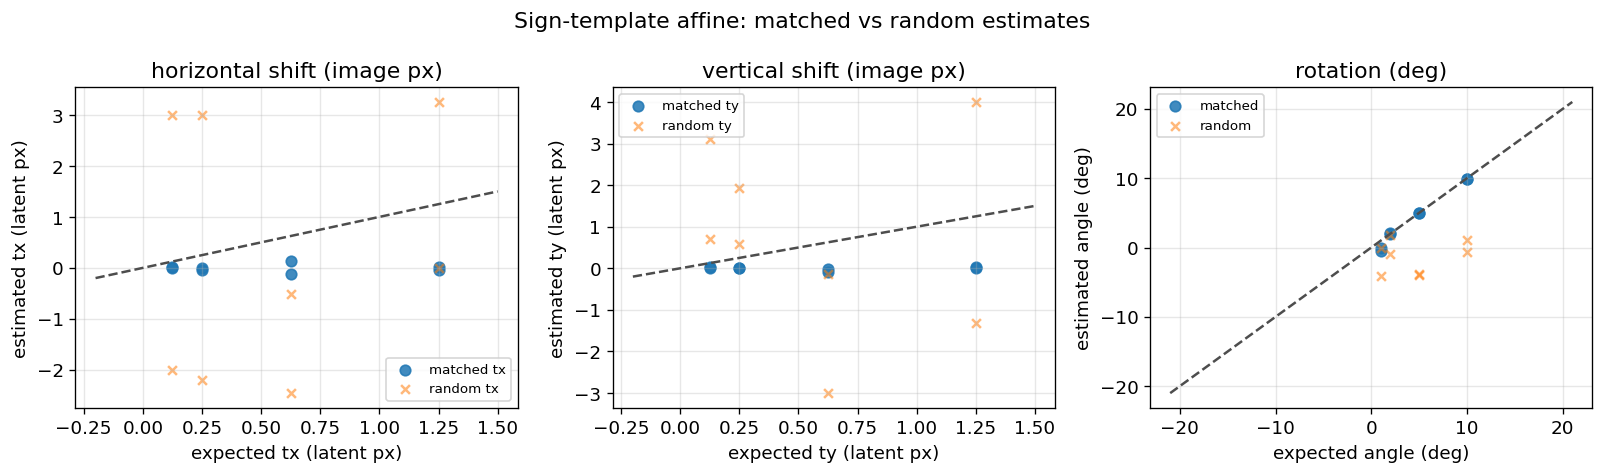

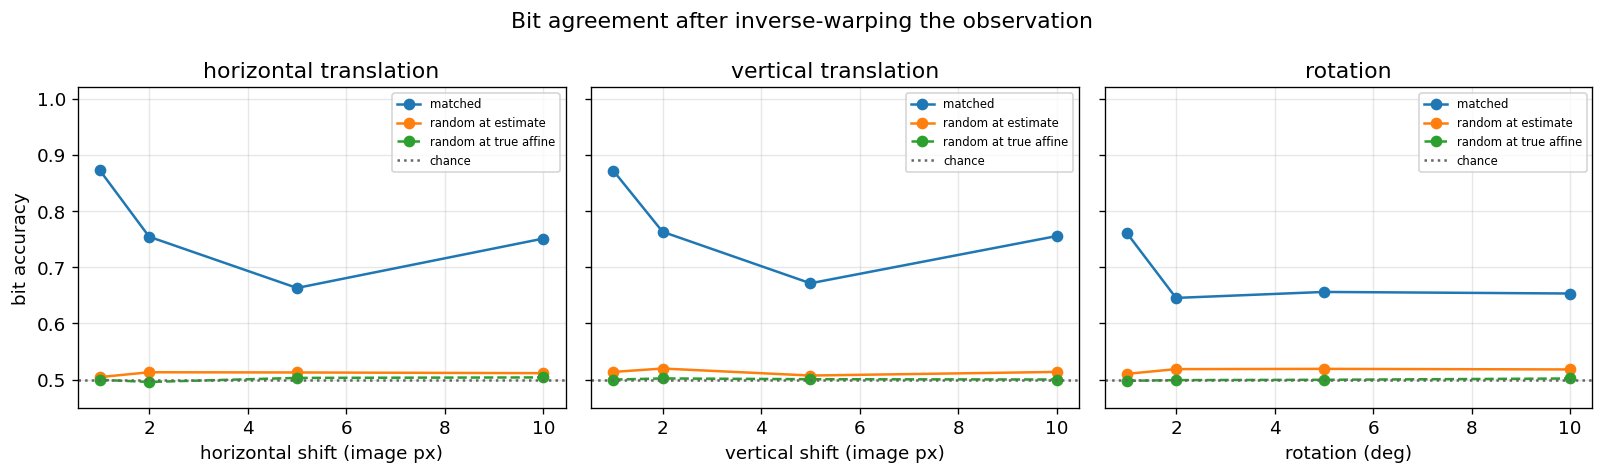

In [5]:
param_summary = (
    results.groupby(["transformation_type", "magnitude"], observed=True)
    .agg(
        n=("sample_id", "count"),
        matched_mean_angle_err=("matched_angle_err", "mean"),
        matched_mean_tx_err=("matched_tx_err", "mean"),
        matched_mean_ty_err=("matched_ty_err", "mean"),
        matched_mean_param_mae=("matched_param_mae", "mean"),
        random_mean_param_mae=("random_param_mae", "mean"),
        matched_mean_bit_accuracy=("matched_bit_accuracy", "mean"),
        random_mean_bit_accuracy=("random_bit_accuracy", "mean"),
        random_bit_accuracy_at_true=("random_bit_accuracy_at_true", "mean"),
        matched_mean_forward_corr=("matched_forward_correlation", "mean"),
        random_mean_forward_corr=("random_forward_correlation", "mean"),
        mean_matched_est_angle=("matched_est_angle_deg", "mean"),
        mean_matched_est_tx=("matched_est_tx", "mean"),
        mean_matched_est_ty=("matched_est_ty", "mean"),
        mean_true_tx=("true_tx", "mean"),
        mean_true_ty=("true_ty", "mean"),
        mean_true_angle=("true_angle_deg", "mean"),
    )
    .reset_index()
)
print(param_summary.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
for ax, kind in zip(axes, FAMILIES):
    block = results.loc[results.transformation_type == kind]
    if kind == "rotation":
        ax.scatter(block.true_angle_deg, block.matched_est_angle_deg, s=40, alpha=0.85, label="matched")
        ax.scatter(block.true_angle_deg, block.random_est_angle_deg, s=28, alpha=0.55, marker="x", label="random")
        lim = (ANGLE_RANGE[0] - 1, ANGLE_RANGE[1] + 1)
        ax.plot(lim, lim, ls="--", color="0.3")
        ax.set_xlabel("expected angle (deg)")
        ax.set_ylabel("estimated angle (deg)")
    elif kind == "horizontal_translation":
        ax.scatter(block.true_tx, block.matched_est_tx, s=40, alpha=0.85, label="matched tx")
        ax.scatter(block.true_tx, block.random_est_tx, s=28, alpha=0.55, marker="x", label="random tx")
        ax.plot([-0.2, 1.5], [-0.2, 1.5], ls="--", color="0.3")
        ax.set_xlabel("expected tx (latent px)")
        ax.set_ylabel("estimated tx (latent px)")
    else:
        ax.scatter(block.true_ty, block.matched_est_ty, s=40, alpha=0.85, label="matched ty")
        ax.scatter(block.true_ty, block.random_est_ty, s=28, alpha=0.55, marker="x", label="random ty")
        ax.plot([-0.2, 1.5], [-0.2, 1.5], ls="--", color="0.3")
        ax.set_xlabel("expected ty (latent px)")
        ax.set_ylabel("estimated ty (latent px)")
    ax.set_title(FAMILY_TITLES[kind])
    ax.legend(fontsize=8)
fig.suptitle("Sign-template affine: matched vs random estimates")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "estimated_vs_expected_params.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), sharey=True)
for ax, kind in zip(axes, FAMILIES):
    block = param_summary.loc[param_summary.transformation_type == kind].sort_values("magnitude")
    ax.plot(block.magnitude, block.matched_mean_bit_accuracy, "-o", label="matched")
    ax.plot(block.magnitude, block.random_mean_bit_accuracy, "-o", label="random at estimate")
    ax.plot(block.magnitude, block.random_bit_accuracy_at_true, "--o", label="random at true affine")
    ax.axhline(0.5, color="0.4", ls=":", label="chance")
    ax.set_xlabel(FAMILY_TITLES[kind])
    ax.set_title(kind.replace("_", " "))
    ax.set_ylim(0.45, 1.02)
    ax.legend(fontsize=7)
axes[0].set_ylabel("bit accuracy")
fig.suptitle("Bit agreement after inverse-warping the observation")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "bit_accuracy_vs_magnitude.png", bbox_inches="tight")
plt.show()


## 5. Correlation with original \(z\) after correction


   transformation_type  magnitude  corr_zhat_vs_z  corr_matched_corrected_vs_z  corr_random_corrected_vs_z  corr_oracle_vs_z  rmse_zhat_vs_z  rmse_matched_corrected_vs_z  rmse_oracle_vs_z  matched_gain_vs_raw
              baseline        0.0          0.8444                       0.8444                      0.8444            0.8444          0.5482                       0.5482            0.5482               0.0000
horizontal_translation        1.0          0.8020                       0.7995                      0.0071            0.7907          0.6176                       0.6152            0.6116              -0.0024
horizontal_translation        2.0          0.6348                       0.6323                      0.0119            0.6007          0.8469                       0.8297            0.8161              -0.0025
horizontal_translation        5.0          0.0942                       0.4275                      0.0108            0.0851          1.3363                       0

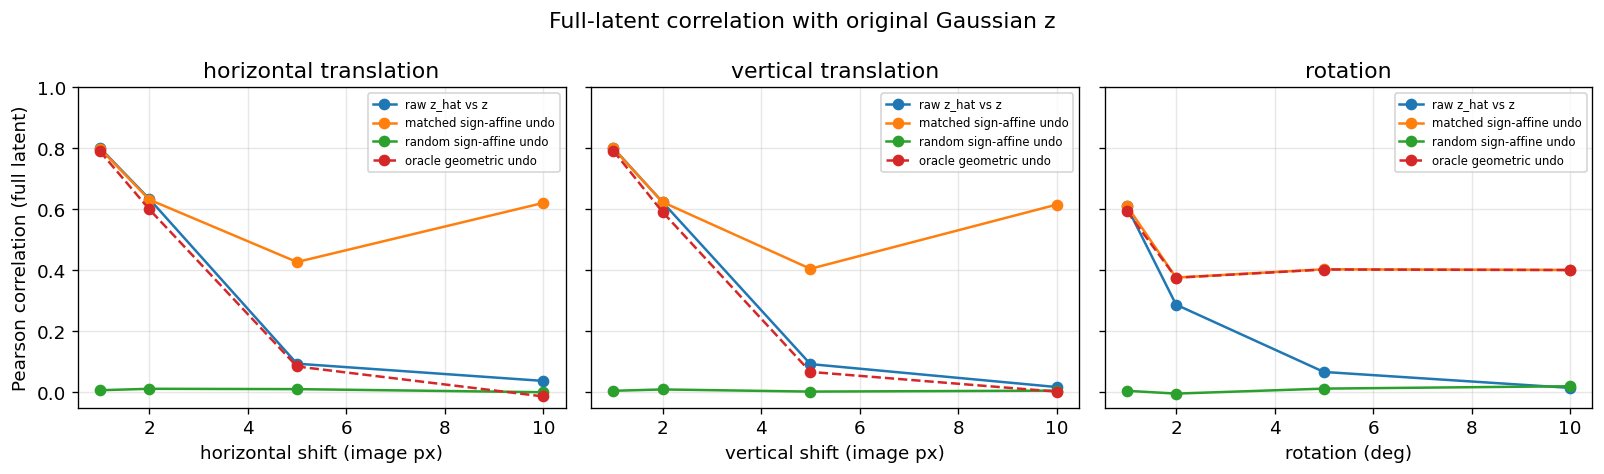

In [6]:
score_summary = (
    results.groupby(["transformation_type", "magnitude"], observed=True)
    .agg(
        corr_zhat_vs_z=("corr_zhat_vs_z", "mean"),
        corr_matched_corrected_vs_z=("corr_matched_corrected_vs_z", "mean"),
        corr_random_corrected_vs_z=("corr_random_corrected_vs_z", "mean"),
        corr_oracle_vs_z=("corr_oracle_vs_z", "mean"),
        rmse_zhat_vs_z=("rmse_zhat_vs_z", "mean"),
        rmse_matched_corrected_vs_z=("rmse_matched_corrected_vs_z", "mean"),
        rmse_oracle_vs_z=("rmse_oracle_vs_z", "mean"),
    )
    .reset_index()
)
score_summary["matched_gain_vs_raw"] = (
    score_summary.corr_matched_corrected_vs_z - score_summary.corr_zhat_vs_z
)
print(score_summary.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), sharey=True)
for ax, kind in zip(axes, FAMILIES):
    block = score_summary.loc[score_summary.transformation_type == kind].sort_values("magnitude")
    ax.plot(block.magnitude, block.corr_zhat_vs_z, "-o", label="raw z_hat vs z")
    ax.plot(block.magnitude, block.corr_matched_corrected_vs_z, "-o", label="matched sign-affine undo")
    ax.plot(block.magnitude, block.corr_random_corrected_vs_z, "-o", label="random sign-affine undo")
    ax.plot(block.magnitude, block.corr_oracle_vs_z, "--o", label="oracle geometric undo")
    ax.set_xlabel(FAMILY_TITLES[kind])
    ax.set_title(kind.replace("_", " "))
    ax.set_ylim(-0.05, 1.0)
    ax.legend(fontsize=7)
axes[0].set_ylabel("Pearson correlation (full latent)")
fig.suptitle("Full-latent correlation with original Gaussian z")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "correlation_vs_z.png", bbox_inches="tight")
plt.show()


## 6. Example panels


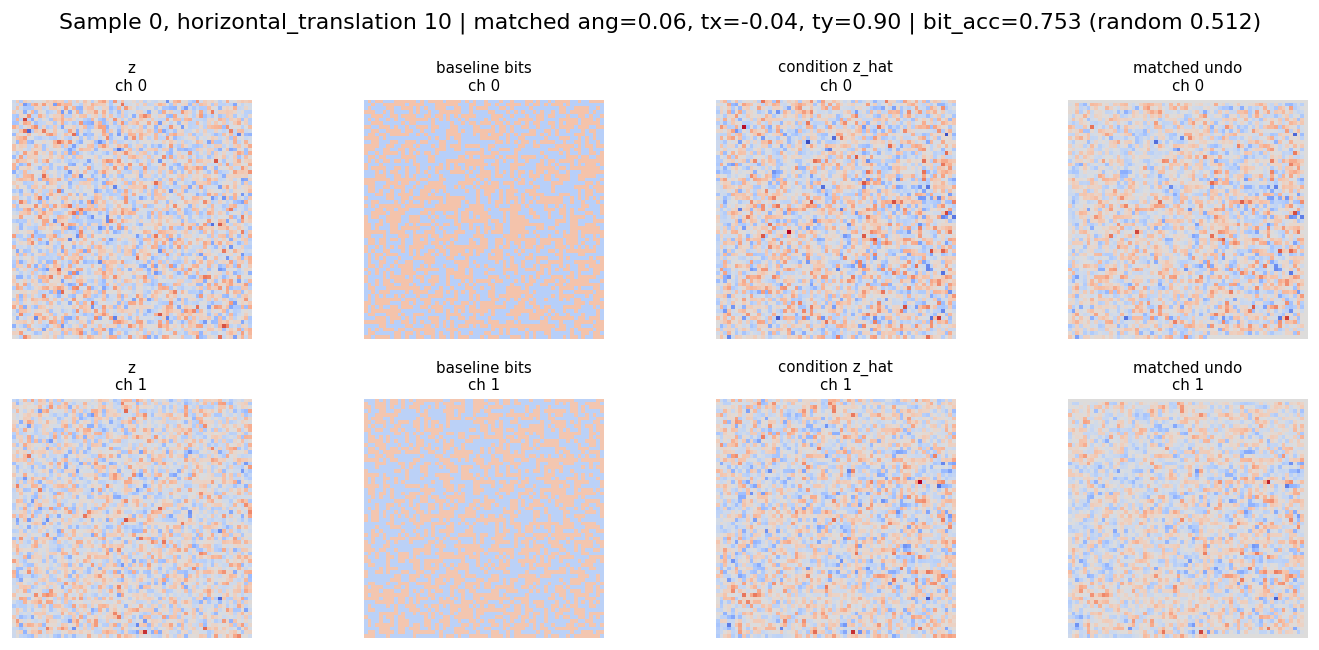

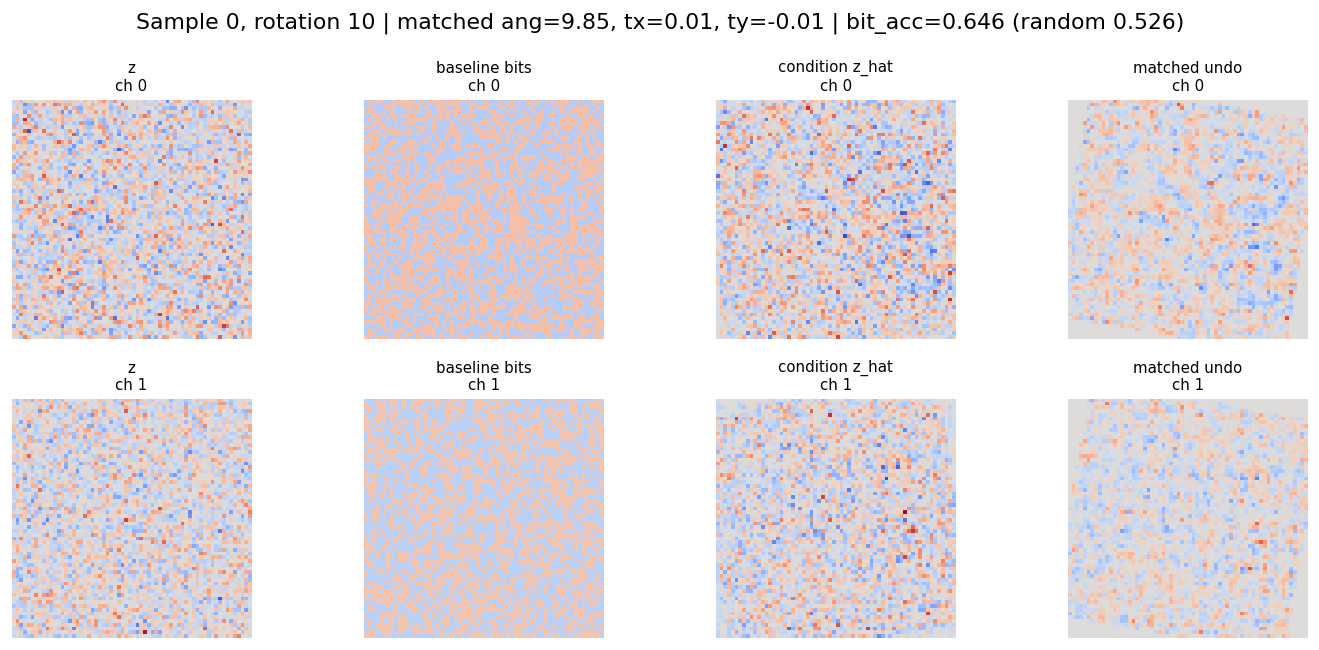

In [7]:
def show_case(kind: str, magnitude: float) -> None:
    blob = blobs[0]
    z = as_chw(blob["z"])
    baseline = as_chw(blob[latent_key("baseline", 0.0)])
    observation = as_chw(blob[latent_key(kind, magnitude)])
    matched_bits = bits_from_latent(baseline)
    row = results.loc[
        (results.sample_id == 0)
        & (results.transformation_type == kind)
        & np.isclose(results.magnitude, magnitude)
    ].iloc[0]
    estimate = np.array([row[f"matched_est_{name}"] for name in PARAM_NAMES], dtype=float)
    corrected = apply_inverse(observation, estimate)

    panels = [
        ("z", z),
        ("baseline bits", bits_to_pm(matched_bits)),
        ("condition z_hat", observation),
        ("matched undo", corrected),
    ]
    fig, axes = plt.subplots(2, 4, figsize=(12, 5.5))
    for channel in (0, 1):
        limit = max(float(np.max(np.abs(img[channel]))) for _, img in panels)
        limit = max(limit, 1e-6)
        for col, (title, img) in enumerate(panels):
            axes[channel, col].imshow(img[channel], cmap="coolwarm", vmin=-limit, vmax=limit)
            axes[channel, col].set_title(f"{title}\nch {channel}", fontsize=9)
            axes[channel, col].axis("off")
    fig.suptitle(
        f"Sample 0, {kind} {magnitude:g} | matched ang={row.matched_est_angle_deg:.2f}, "
        f"tx={row.matched_est_tx:.2f}, ty={row.matched_est_ty:.2f} | "
        f"bit_acc={row.matched_bit_accuracy:.3f} (random {row.random_bit_accuracy:.3f})"
    )
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"example_sample0_{kind}_{magnitude:g}.png", bbox_inches="tight")
    plt.show()


show_case("horizontal_translation", 10.0)
show_case("rotation", 10.0)


## 7. Interpretation

Matched bits should recover geometry better than chance and beat the random arm. Random bit accuracy near \(1/2\) means the optimizer is not inventing a lock from an unrelated sign field.


In [8]:
metadata = {
    "source_run": str(RUN_DIR),
    "n_samples": N_SAMPLES,
    "max_samples_cap": MAX_SAMPLES,
    "vae_scale_factor": VAE_SCALE,
    "template_access": "sign-only 0/1 bits from baseline z_hat",
    "observation_access": "full signed condition z_hat",
    "optimizer": "maximize multi-channel corr(warp(B_pm), Y); coarse grids + L-BFGS-B; no DE",
    "random_control": "independent 0/1 field per sample, same shape as latent",
    "expected_transform": "horizontal/vertical: translation magnitude/8; rotation: same angle; scale=1 shear=0",
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
param_summary.to_csv(OUTPUT_DIR / "param_summary.csv", index=False)
score_summary.to_csv(OUTPUT_DIR / "score_summary.csv", index=False)

print("Interpretation")
base = results.loc[results.transformation_type == "baseline"]
print(
    f"- Baseline matched bit accuracy={base.matched_bit_accuracy.mean():.3f}; "
    f"random at identity={base.random_bit_accuracy.mean():.3f} (chance=0.5)."
)
nonbase = results.loc[results.transformation_type != "baseline"]
print(
    f"- Non-baseline matched bit accuracy={nonbase.matched_bit_accuracy.mean():.3f}; "
    f"random={nonbase.random_bit_accuracy.mean():.3f}; "
    f"random at true affine={nonbase.random_bit_accuracy_at_true.mean():.3f}."
)
rot = results.loc[results.transformation_type == "rotation"]
print(
    f"- Rotations: matched mean |angle error|={rot.matched_angle_err.mean():.3f} deg, "
    f"random={rot.random_angle_err.mean():.3f} deg."
)
shift = results.loc[results.transformation_type.isin(["horizontal_translation", "vertical_translation"])]
print(
    f"- Translations: matched mean |tx| err={shift.matched_tx_err.mean():.3f}, "
    f"|ty| err={shift.matched_ty_err.mean():.3f}; "
    f"random |tx|={shift.random_tx_err.mean():.3f}, |ty|={shift.random_ty_err.mean():.3f}."
)
gap = nonbase.matched_bit_accuracy.mean() - nonbase.random_bit_accuracy.mean()
print(f"- Matched-minus-random bit-accuracy gap (non-baseline): {gap:.3f}.")
print(f"- Wrote summaries under {OUTPUT_DIR}")


Interpretation
- Baseline matched bit accuracy=1.000; random at identity=0.496 (chance=0.5).
- Non-baseline matched bit accuracy=0.735; random=0.513; random at true affine=0.500.
- Rotations: matched mean |angle error|=0.366 deg, random=5.836 deg.
- Translations: matched mean |tx| err=0.525, |ty| err=0.515; random |tx|=2.400, |ty|=2.115.
- Matched-minus-random bit-accuracy gap (non-baseline): 0.221.
- Wrote summaries under results\latent_affine_registration_sign_template
